In [ ]:
import numpy as np
import pandas as pd
import torch

### Problem 1: Temperature Prediction Using a Non-Linear Model

In [ ]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

In [ ]:
def model(t_u, w1, w2, b):
  return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
  squared_diffs = (t_p - t_c)**2
  return squared_diffs.mean()

params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)

def training_loop(n_epochs, learning_rate, params, t_u, t_c):
  for epoch in range(1, n_epochs + 1):
    if params.grad is not None:
      params.grad.zero_()

    t_p = model(t_u, *params)
    loss = loss_fn(t_p, t_c)
    loss.backward()

    with torch.no_grad():
      params -= learning_rate * params.grad

    if epoch % 500 == 0:
      print('Epoch %d, Loss %f' % (epoch, float(loss)))
  return params

t_un = 0.1 * t_u

### Training Sessions for Learning Rate Below

In [ ]:
training_loop (
    n_epochs = 5000,
    learning_rate = 1e-1,
    params = torch.tensor([1.0, 1.0, 0], requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan


tensor([nan, nan, nan], requires_grad=True)

In [ ]:
training_loop (
    n_epochs = 5000,
    learning_rate = 1e-2,
    params = torch.tensor([1.0, 1.0, 0], requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan


tensor([nan, nan, nan], requires_grad=True)

In [ ]:
training_loop (
    n_epochs = 5000,
    learning_rate = 1e-3,
    params = torch.tensor([1.0, 1.0, 0], requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan


tensor([nan, nan, nan], requires_grad=True)

In [ ]:
training_loop (
    n_epochs = 5000,
    learning_rate = 1e-4,
    params = torch.tensor([1.0, 1.0, 0], requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123477
Epoch 2500, Loss 5.377227
Epoch 3000, Loss 4.845285
Epoch 3500, Loss 4.465788
Epoch 4000, Loss 4.194724
Epoch 4500, Loss 4.000802
Epoch 5000, Loss 3.861744


tensor([-0.8881,  0.5570, -0.8753], requires_grad=True)

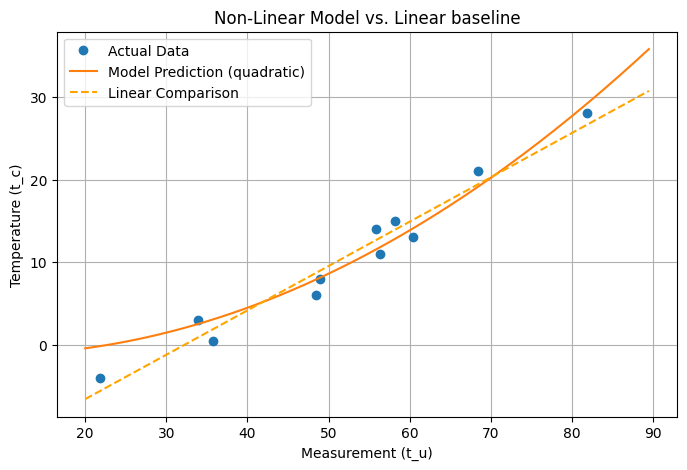

In [ ]:
import matplotlib.pyplot as plt

# Best parameters obtained from 1e-4 training loop
best_params = torch.tensor([-0.8881,  0.5570, -0.8753])

# Generate points for plotting the model's curve smoothly
t_u_range = torch.arange(20.0, 90.0, 0.5)
t_un_range = 0.1 * t_u_range
t_p_range = model(t_un_range, *best_params)

# Linear comparison equation: 0.5367 * t_u - 17.3021
linear_p_range = 0.5367 * t_u_range - 17.3021

# Create the plot
plt.figure(figsize=(8, 5))
plt.plot(t_u.numpy(), t_c.numpy(), 'o', label='Actual Data')
plt.plot(t_u_range.numpy(), t_p_range.detach().numpy(), '-', label='Model Prediction (quadratic)')
plt.plot(t_u_range.numpy(), linear_p_range.numpy(), '--', label='Linear Comparison', color='orange')
plt.xlabel('Measurement (t_u)')
plt.ylabel('Temperature (t_c)')
plt.title('Non-Linear Model vs. Linear baseline')
plt.legend()
plt.grid(True)
plt.show()

### Problem 2: Using PyTorch to Train a Linear Regression Model to Predict House Prices Using Select Parameters

In [ ]:
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv'
df = pd.read_csv(url)
print(df.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [ ]:
features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
X_raw = df[features].values
y_raw = df['price'].values

X = torch.tensor(X_raw, dtype=torch.float32)
y = torch.tensor(y_raw, dtype=torch.float32).unsqueeze(1)

X_min, _ = torch.min(X, dim=0)
X_max, _ = torch.max(X, dim=0)
X_n = (X - X_min) / (X_max - X_min)

y_min = torch.min(y)
y_max = torch.max(y)
y_n = (y - y_min) / (y_max - y_min)

n_samples = X_n.shape[0]
n_val = int(0.2 * n_samples)

torch.manual_seed(42)
shuffled_indices = torch.randperm(n_samples)

val_indices = shuffled_indices[:n_val]
train_indices = shuffled_indices[n_val:]

X_train, y_train = X_n[train_indices], y_n[train_indices]

X_val, y_val = X_n[val_indices], y_n[val_indices]


In [ ]:
def lin_model(X, w, b):
    return torch.matmul(X, w) + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

def training_loop_housing(n_epochs, learning_rate, params, X_train, y_train, X_val, y_val):
    w = params[:-1].clone().detach().unsqueeze(1).requires_grad_(True)
    b = params[-1].clone().detach().requires_grad_(True)

    for epoch in range(1, n_epochs + 1):
        if w.grad is not None:
            w.grad.zero_()
        if b.grad is not None:
            b.grad.zero_()

        t_p_train = lin_model(X_train, w, b)
        loss_train = loss_fn(t_p_train, y_train)
        loss_train.backward()

        with torch.no_grad():
            w -= learning_rate * w.grad
            b -= learning_rate * b.grad

            t_p_val = lin_model(X_val, w, b)
            loss_val = loss_fn(t_p_val, y_val)

        if epoch % 500 == 0 or epoch == 1:
            print(f"Epoch {epoch}, Training Loss: {loss_train.item():.6f}, Validation Loss: {loss_val.item():.6f}")

    return torch.cat([w.squeeze(), b.unsqueeze(0)])

### Training Sessions for Learning Rate Below


In [ ]:
init_params = torch.zeros(6, dtype=torch.float32)

final_params = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-1,
    params = init_params,
    X_train = X_train,
    y_train = y_train,
    X_val = X_val,
    y_val = y_val
)
final_params

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.063755
Epoch 500, Training Loss: 0.011979, Validation Loss: 0.010096
Epoch 1000, Training Loss: 0.011922, Validation Loss: 0.009922
Epoch 1500, Training Loss: 0.011921, Validation Loss: 0.009906
Epoch 2000, Training Loss: 0.011921, Validation Loss: 0.009904
Epoch 2500, Training Loss: 0.011921, Validation Loss: 0.009903
Epoch 3000, Training Loss: 0.011921, Validation Loss: 0.009903
Epoch 3500, Training Loss: 0.011921, Validation Loss: 0.009903
Epoch 4000, Training Loss: 0.011921, Validation Loss: 0.009903
Epoch 4500, Training Loss: 0.011921, Validation Loss: 0.009903
Epoch 5000, Training Loss: 0.011921, Validation Loss: 0.009903


tensor([0.4172, 0.0917, 0.2566, 0.1369, 0.0975, 0.0415],
       grad_fn=<CatBackward0>)

In [ ]:
init_params = torch.zeros(6, dtype=torch.float32)

final_params = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-2,
    params = init_params,
    X_train = X_train,
    y_train = y_train,
    X_val = X_val,
    y_val = y_val
)
final_params

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.095864
Epoch 500, Training Loss: 0.015181, Validation Loss: 0.015455
Epoch 1000, Training Loss: 0.013657, Validation Loss: 0.012943
Epoch 1500, Training Loss: 0.012967, Validation Loss: 0.011803
Epoch 2000, Training Loss: 0.012588, Validation Loss: 0.011178
Epoch 2500, Training Loss: 0.012356, Validation Loss: 0.010793
Epoch 3000, Training Loss: 0.012209, Validation Loss: 0.010540
Epoch 3500, Training Loss: 0.012112, Validation Loss: 0.010367
Epoch 4000, Training Loss: 0.012049, Validation Loss: 0.010246
Epoch 4500, Training Loss: 0.012007, Validation Loss: 0.010160
Epoch 5000, Training Loss: 0.011979, Validation Loss: 0.010097


tensor([0.3666, 0.1036, 0.2439, 0.1392, 0.1094, 0.0470],
       grad_fn=<CatBackward0>)

In [ ]:
init_params = torch.zeros(6, dtype=torch.float32)

final_params = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-3,
    params = init_params,
    X_train = X_train,
    y_train = y_train,
    X_val = X_val,
    y_val = y_val
)
final_params

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.099571
Epoch 500, Training Loss: 0.023670, Validation Loss: 0.026845
Epoch 1000, Training Loss: 0.018529, Validation Loss: 0.020818
Epoch 1500, Training Loss: 0.017683, Validation Loss: 0.019534
Epoch 2000, Training Loss: 0.017176, Validation Loss: 0.018708
Epoch 2500, Training Loss: 0.016742, Validation Loss: 0.018003
Epoch 3000, Training Loss: 0.016356, Validation Loss: 0.017377
Epoch 3500, Training Loss: 0.016011, Validation Loss: 0.016817
Epoch 4000, Training Loss: 0.015703, Validation Loss: 0.016315
Epoch 4500, Training Loss: 0.015426, Validation Loss: 0.015864
Epoch 5000, Training Loss: 0.015178, Validation Loss: 0.015457


tensor([0.1228, 0.0945, 0.0897, 0.1146, 0.1079, 0.1351],
       grad_fn=<CatBackward0>)

In [ ]:
init_params = torch.zeros(6, dtype=torch.float32)

final_params = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-4,
    params = init_params,
    X_train = X_train,
    y_train = y_train,
    X_val = X_val,
    y_val = y_val
)
final_params

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.099947
Epoch 500, Training Loss: 0.075444, Validation Loss: 0.081652
Epoch 1000, Training Loss: 0.062026, Validation Loss: 0.067624
Epoch 1500, Training Loss: 0.051790, Validation Loss: 0.056883
Epoch 2000, Training Loss: 0.043978, Validation Loss: 0.048650
Epoch 2500, Training Loss: 0.038011, Validation Loss: 0.042331
Epoch 3000, Training Loss: 0.033451, Validation Loss: 0.037473
Epoch 3500, Training Loss: 0.029962, Validation Loss: 0.033730
Epoch 4000, Training Loss: 0.027289, Validation Loss: 0.030841
Epoch 4500, Training Loss: 0.025238, Validation Loss: 0.028603
Epoch 5000, Training Loss: 0.023661, Validation Loss: 0.026863


tensor([0.0453, 0.0613, 0.0233, 0.0502, 0.0455, 0.1388],
       grad_fn=<CatBackward0>)

###Problem 3: Using PyTorch to Train a Linear Regression Model to Predict House Prices Using All Parameters

In [ ]:
df_all = df.copy()

binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    df_all[col] = df_all[col].map({'yes': 1, 'no': 0})

df_all = pd.get_dummies(df_all, columns=['furnishingstatus'], drop_first=False)

feature_cols = [col for col in df_all.columns if col != 'price']

X_raw_all = df_all[feature_cols].values.astype(np.float32)
y_raw_all = df_all['price'].values.astype(np.float32)

X_all = torch.tensor(X_raw_all, dtype=torch.float32)
y_all = torch.tensor(y_raw_all, dtype=torch.float32).unsqueeze(1)

X_all_min, _ = torch.min(X_all, dim=0)
X_all_max, _ = torch.max(X_all, dim=0)

X_all_max_clamped = torch.where(X_all_max == X_all_min, X_all_max + 1e-8, X_all_max)
X_all_n = (X_all - X_all_min) / (X_all_max_clamped - X_all_min)

y_all_min = torch.min(y_all)
y_all_max = torch.max(y_all)
y_all_n = (y_all - y_all_min) / (y_all_max - y_all_min)

torch.manual_seed(42)
shuffled_indices_all = torch.randperm(X_all_n.shape[0])

n_val_all = int(0.2 * X_all_n.shape[0])
val_indices_all = shuffled_indices_all[:n_val_all]
train_indices_all = shuffled_indices_all[n_val_all:]

X_train_all, y_train_all = X_all_n[train_indices_all], y_all_n[train_indices_all]
X_val_all, y_val_all = X_all_n[val_indices_all], y_all_n[val_indices_all]

print(f"All features count: {len(feature_cols)}")
print(f"Features: {feature_cols}")

All features count: 14
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_furnished', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


###Training Sessions for Learning Rate Below


In [ ]:
num_features_all = X_train_all.shape[1]
init_params_all = torch.zeros(num_features_all + 1, dtype=torch.float32)

final_params_all = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-1,
    params = init_params_all,
    X_train = X_train_all,
    y_train = y_train_all,
    X_val = X_val_all,
    y_val = y_val_all
)
final_params_all

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.035175
Epoch 500, Training Loss: 0.008781, Validation Loss: 0.007206
Epoch 1000, Training Loss: 0.008740, Validation Loss: 0.007037
Epoch 1500, Training Loss: 0.008738, Validation Loss: 0.007017
Epoch 2000, Training Loss: 0.008738, Validation Loss: 0.007013
Epoch 2500, Training Loss: 0.008738, Validation Loss: 0.007012
Epoch 3000, Training Loss: 0.008738, Validation Loss: 0.007012
Epoch 3500, Training Loss: 0.008738, Validation Loss: 0.007012
Epoch 4000, Training Loss: 0.008738, Validation Loss: 0.007012
Epoch 4500, Training Loss: 0.008738, Validation Loss: 0.007012
Epoch 5000, Training Loss: 0.008738, Validation Loss: 0.007012


tensor([ 0.3021,  0.0627,  0.2237,  0.1116,  0.0413,  0.0292,  0.0330,  0.0895,
         0.0745,  0.0672,  0.0525,  0.0113,  0.0123, -0.0188,  0.0048],
       grad_fn=<CatBackward0>)

In [ ]:
num_features_all = X_train_all.shape[1]
init_params_all = torch.zeros(num_features_all + 1, dtype=torch.float32)

final_params_all = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-2,
    params = init_params_all,
    X_train = X_train_all,
    y_train = y_train_all,
    X_val = X_val_all,
    y_val = y_val_all
)
final_params_all

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.091227
Epoch 500, Training Loss: 0.010832, Validation Loss: 0.010888
Epoch 1000, Training Loss: 0.009834, Validation Loss: 0.009161
Epoch 1500, Training Loss: 0.009398, Validation Loss: 0.008413
Epoch 2000, Training Loss: 0.009162, Validation Loss: 0.007994
Epoch 2500, Training Loss: 0.009019, Validation Loss: 0.007729
Epoch 3000, Training Loss: 0.008928, Validation Loss: 0.007550
Epoch 3500, Training Loss: 0.008868, Validation Loss: 0.007422
Epoch 4000, Training Loss: 0.008827, Validation Loss: 0.007329
Epoch 4500, Training Loss: 0.008800, Validation Loss: 0.007260
Epoch 5000, Training Loss: 0.008781, Validation Loss: 0.007207


tensor([ 0.2561,  0.0752,  0.2109,  0.1112,  0.0447,  0.0312,  0.0322,  0.0892,
         0.0768,  0.0753,  0.0548,  0.0121,  0.0128, -0.0190,  0.0059],
       grad_fn=<CatBackward0>)

In [ ]:
num_features_all = X_train_all.shape[1]
init_params_all = torch.zeros(num_features_all + 1, dtype=torch.float32)

final_params_all = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-3,
    params = init_params_all,
    X_train = X_train_all,
    y_train = y_train_all,
    X_val = X_val_all,
    y_val = y_val_all
)
final_params_all

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.099090
Epoch 500, Training Loss: 0.015297, Validation Loss: 0.018417
Epoch 1000, Training Loss: 0.013829, Validation Loss: 0.016300
Epoch 1500, Training Loss: 0.013027, Validation Loss: 0.014943
Epoch 2000, Training Loss: 0.012460, Validation Loss: 0.013924
Epoch 2500, Training Loss: 0.012035, Validation Loss: 0.013135
Epoch 3000, Training Loss: 0.011701, Validation Loss: 0.012505
Epoch 3500, Training Loss: 0.011428, Validation Loss: 0.011992
Epoch 4000, Training Loss: 0.011199, Validation Loss: 0.011564
Epoch 4500, Training Loss: 0.011002, Validation Loss: 0.011202
Epoch 5000, Training Loss: 0.010830, Validation Loss: 0.010890


tensor([ 0.0773,  0.0580,  0.0736,  0.0856,  0.0592,  0.0409,  0.0304,  0.0395,
         0.0884,  0.0697,  0.0585,  0.0363,  0.0291, -0.0158,  0.0496],
       grad_fn=<CatBackward0>)

In [ ]:
num_features_all = X_train_all.shape[1]
init_params_all = torch.zeros(num_features_all + 1, dtype=torch.float32)

final_params_all = training_loop_housing(
    n_epochs = 5000,
    learning_rate = 1e-4,
    params = init_params_all,
    X_train = X_train_all,
    y_train = y_train_all,
    X_val = X_val_all,
    y_val = y_val_all
)
final_params_all

Epoch 1, Training Loss: 0.092999, Validation Loss: 0.099898
Epoch 500, Training Loss: 0.059936, Validation Loss: 0.065476
Epoch 1000, Training Loss: 0.041025, Validation Loss: 0.045739
Epoch 1500, Training Loss: 0.030203, Validation Loss: 0.034404
Epoch 2000, Training Loss: 0.023977, Validation Loss: 0.027850
Epoch 2500, Training Loss: 0.020364, Validation Loss: 0.024018
Epoch 3000, Training Loss: 0.018238, Validation Loss: 0.021736
Epoch 3500, Training Loss: 0.016960, Validation Loss: 0.020340
Epoch 4000, Training Loss: 0.016166, Validation Loss: 0.019450
Epoch 4500, Training Loss: 0.015651, Validation Loss: 0.018851
Epoch 5000, Training Loss: 0.015296, Validation Loss: 0.018421


tensor([0.0296, 0.0384, 0.0174, 0.0345, 0.0765, 0.0250, 0.0353, 0.0082, 0.0459,
        0.0303, 0.0317, 0.0309, 0.0369, 0.0134, 0.0812],
       grad_fn=<CatBackward0>)